# Naloga 1.1 – Praštevila: analiza

Meritve izvajata programa `vaja1_1_lcg_test` (generator LCG) in `vaja1_1_prime_bench` (tvorba praštevil).
Pred zagonom zvezka ju zgradite v CLionu.

In [2]:
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# Folder with the built executables, None searches cmake-build-*/vaja1_1 in the repository
BUILD_DIR = None
SEED = 0

REPO_ROOT = Path.cwd().resolve().parents[1]
EXE_SUFFIX = ".exe" if sys.platform == "win32" else ""


def find_executable(name: str) -> Path:
    if BUILD_DIR is not None:
        return Path(BUILD_DIR) / f"{name}{EXE_SUFFIX}"
    for build_dir in sorted(REPO_ROOT.glob("cmake-build-*")):
        candidate = build_dir / "vaja1_1" / f"{name}{EXE_SUFFIX}"
        if candidate.exists():
            return candidate
    raise FileNotFoundError(f"{name} not found in cmake-build-*/vaja1_1, build it first or set BUILD_DIR")


def run(name: str, *args) -> str:
    exe = find_executable(name)
    result = subprocess.run([str(exe), *map(str, args)], capture_output=True, text=True)
    if result.returncode != 0:
        raise RuntimeError(f"{exe.name} failed with exit code {result.returncode:#x}: {result.stderr.strip()}")
    return result.stdout

## 1. Analiza generatorja naključnih števil

Z generatorjem Super–Duper LCG(2³², 69069, 1, 0) tvorimo 1 milijon naključnih števil z intervala [1, 1000]
in preštejemo, kolikokrat se pojavi posamezno število.

In [3]:
M, A, B = 2**32, 69069, 1
LOW, HIGH = 1, 1000
COUNT = 1_000_000

numbers = np.array(run("vaja1_1_lcg_test", M, A, B, SEED, LOW, HIGH, COUNT).split(), dtype=np.int64)
values = np.arange(LOW, HIGH + 1)
counts = np.bincount(numbers - LOW, minlength=len(values))

expected = COUNT / len(values)
chi2 = np.sum((counts - expected) ** 2 / expected)

print(f"expected per value: {expected:.2f}")
print(f"min count: {counts.min()} (value {values[counts.argmin()]})")
print(f"max count: {counts.max()} (value {values[counts.argmax()]})")
print(f"standard deviation of counts: {counts.std():.2f}")
print(f"chi-squared: {chi2:.2f} with {len(values) - 1} degrees of freedom")

expected per value: 1000.00
min count: 905 (value 531)
max count: 1089 (value 706)
standard deviation of counts: 31.09
chi-squared: 966.45 with 999 degrees of freedom


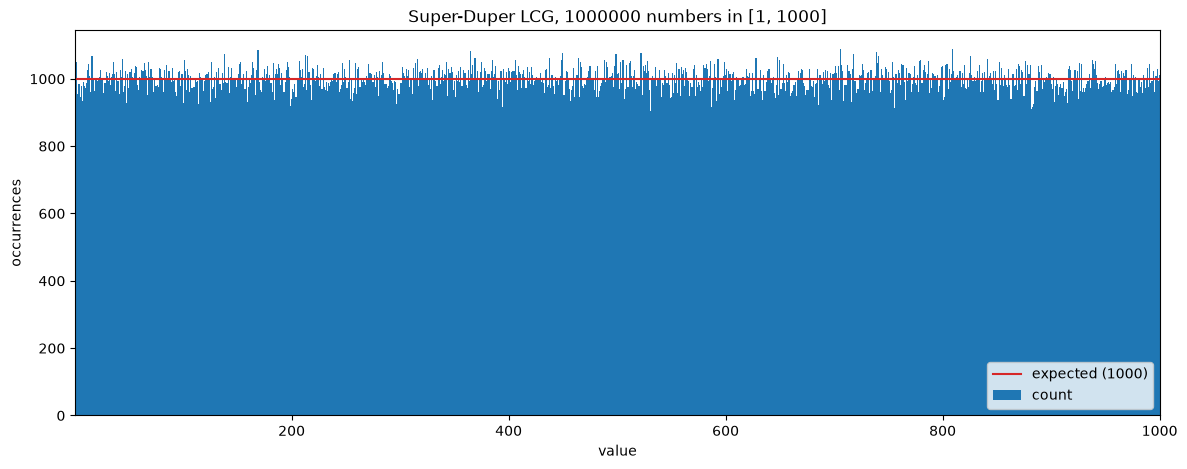

In [4]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.bar(values, counts, width=1.0, color="tab:blue", label="count")
ax.axhline(expected, color="tab:red", label=f"expected ({expected:.0f})")
ax.set_xlim(LOW - 0.5, HIGH + 0.5)
ax.set_xlabel("value")
ax.set_ylabel("occurrences")
ax.set_title(f"Super-Duper LCG, {COUNT} numbers in [{LOW}, {HIGH}]")
ax.legend(loc="lower right")
plt.show()

**Komentar:** _TODO_

## 2. Časovna zahtevnost glede na število bitov

Za vsak n od 4 do 32 tvorimo `REPETITIONS` n-bitnih praštevil z obema metodama in izmerimo povprečni čas tvorbe
enega praštevila. Miller–Rabinov test uporablja `MR_S` ponovitev.

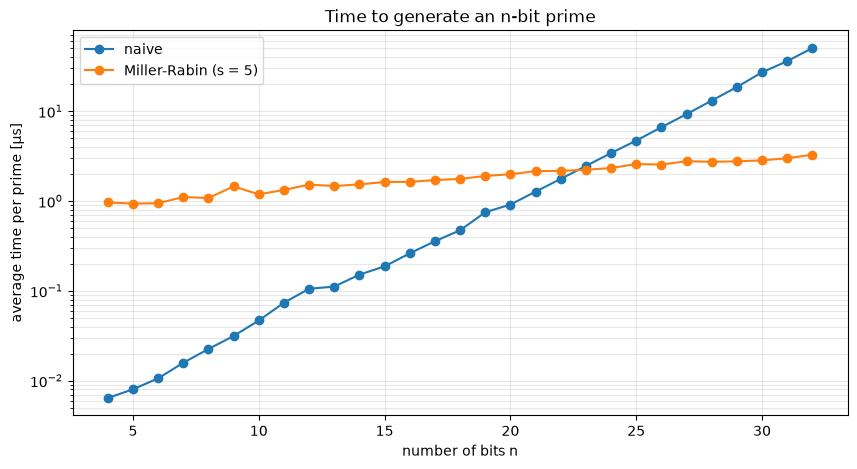

In [ ]:
BITS = range(4, 33)
MR_S = 20
REPETITIONS = 1000

naive_times = [float(run("vaja1_1_prime_bench", "naive", bits, MR_S, REPETITIONS, SEED)) for bits in BITS]
mr_times = [float(run("vaja1_1_prime_bench", "mr", bits, MR_S, REPETITIONS, SEED)) for bits in BITS]

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(BITS, naive_times, marker="o", label="naive")
ax.plot(BITS, mr_times, marker="o", label=f"Miller-Rabin (s = {MR_S})")
ax.set_yscale("log")
ax.set_xlabel("number of bits n")
ax.set_ylabel("average time per prime [µs]")
ax.set_title("Time to generate an n-bit prime")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
plt.show()

**Komentar:** _TODO_

## 3. Časovna zahtevnost Miller–Rabinovega testa glede na parameter s

Tvorimo 32-bitna praštevila z Miller–Rabinovim testom za s od 1 do 20.

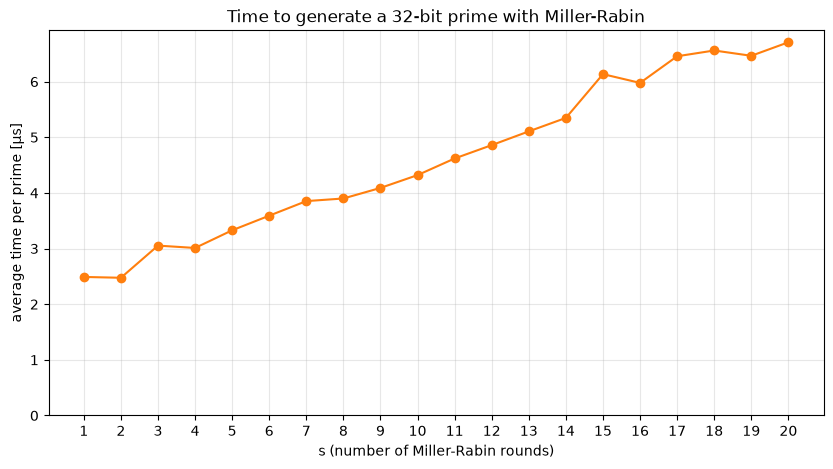

In [7]:
S_VALUES = range(1, 21)
REPETITIONS_S = 10000

s_times = [float(run("vaja1_1_prime_bench", "mr", 32, s, REPETITIONS_S, SEED)) for s in S_VALUES]

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(S_VALUES, s_times, marker="o", color="tab:orange")
ax.set_xticks(list(S_VALUES))
ax.set_ylim(bottom=0)
ax.set_xlabel("s (number of Miller-Rabin rounds)")
ax.set_ylabel("average time per prime [µs]")
ax.set_title("Time to generate a 32-bit prime with Miller-Rabin")
ax.grid(True, alpha=0.3)
plt.show()

**Komentar:** _TODO_